# 05 - Antibiotic degradation and nutrient recycling: κ_b, d_a, φ_max, ξ

**Question.** How do the three routes of antibiotic removal (free enzyme κ_b, basal decay d_a,
living resistant cells φ_max) and nutrient recycling from lysed cells (ξ) change the crash, the
recovery and the final composition?

**Sweep.** 21 × 21 × 21 × 21 = 194,481 runs at the Fig. 2C dose (a0 = 2.15, i = 10); all other
parameters at their SI base values. κ_b, φ_max and ξ span their SI randomized ranges. **d_a is not
randomized in the paper**; the range 0-0.1 (0 to 5 times its base value) is the group's own choice.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
TABLES = PROJECT_ROOT / "results" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None); pd.set_option("display.width", 160)

from dataclasses import replace
from src.model.ma2024_model import DEFAULT_PARAMS, BASE_A0, BASE_I
from src.analysis import sweep_engine as engine
from src.analysis.grid_runner import axis, BASE_VALUES, RANGES, LOG_AXES
from src.analysis.plotting import (heatmap_slices, pair_heatmaps, marginal_effects, outcome_map,
                                   outcome_counts, timecourses, select, label, SHORT, OKABE_ITO, OUTCOME_COLORS)

PARAMS = ['kappa_b', 'd_a', 'phi_max', 'xi']
df = pd.read_csv(TABLES / "grid_kappab_da_phimax_xi.csv.gz")
with np.errstate(divide="ignore"):
    df["log10_f_R"] = np.log10(df.f_R_final)
    df["log10_ns_min"] = np.log10(df.ns_min.clip(lower=1e-30))
    df["log10_nr_min"] = np.log10(df.nr_min.clip(lower=1e-30))
settled = df[~df.outcome.isin(["community collapsed", "not converged"])]
print(f"{len(df):,} runs; {len(settled):,} settled; fixed dose: " +
      ", ".join(f"{k} = {BASE_VALUES[k]:g}" for k in ("a0", "i") if k not in PARAMS))
pd.DataFrame([{"parameter": k, "base": BASE_VALUES[k], "min": df[k].min(), "max": df[k].max(),
               "values": df[k].nunique(), "spacing": "log" if k in LOG_AXES else "linear"} for k in PARAMS])

194,481 runs; 194,128 settled; fixed dose: a0 = 2.15, i = 10


,parameter,base,min,max,values,spacing
0,kappa_b,0.35,0.0,1.0,21,linear
1,d_a,0.02,0.0,0.1,21,linear
2,phi_max,1.00,0.0,5.0,21,linear
3,xi,0.80,0.0,1.0,21,linear


## Overview of the endpoints

Minimum, median and maximum over the settled runs, and the value at the base point.

In [2]:
cols = ["f_R_final", "diversity_final", "total_final", "peak_loss_S", "peak_loss_total",
        "t_regain_S", "t_90_final_S", "t_steady_state"]
overview = settled[cols].describe().T[["min", "50%", "max"]].rename(columns={"50%": "median"})
base = select(df, {k: BASE_VALUES[k] for k in PARAMS})
overview["base point"] = base[cols].iloc[0].values
overview.index = [label(c) for c in cols]
print(f"S viable at the end: {df.sensitive_survives.mean():.1%} of runs | R gained share (f_R rose): "
      f"{(df.delta_log_ratio > 0).mean():.1%} | needed a horizon beyond 150: {(df.t_end > 150).mean():.1%}")
overview.round(3)

S viable at the end: 96.9% of runs | R gained share (f_R rose): 0.0% | needed a horizon beyond 150: 0.2%


,min,median,max,base point
Final resistant fraction f_R,0.000,0.454,0.463,0.433
Final Shannon diversity H,0.000,0.689,0.690,0.684
Final total density,0.019,3.720,4.400,3.832
Peak S loss,0.110,0.204,1.000,0.394
Peak total loss,0.115,0.213,1.000,0.410
S recovery time (back to start),2.000,4.000,1002.000,8.500
Time for S to reach 90% of final,0.000,8.000,1070.000,13.500
Time to steady state,7.500,10.000,1138.000,15.500


## Outcome classes

**Plain model:** the paper's equations as they are. **With floor:** a population that falls below
one cell (10⁻⁹ of the carrying capacity) is removed for good. The two only differ when a run passes
through a very deep crash.

In [3]:
both = pd.concat([outcome_counts(df, "outcome").add_prefix("plain model: "),
                  outcome_counts(df, "outcome_floor").add_prefix("with floor: ")], axis=1).fillna(0)
both

,plain model: runs,plain model: % of grid,with floor: runs,with floor: % of grid
R suppressed,1.0,0.00,1.0,0.00
"S viable, R persists",188539.0,96.94,188539.0,96.94
"S not viable, R persists",5588.0,2.87,5588.0,2.87
community collapsed,350.0,0.18,0.0,0.00
not converged,3.0,0.00,0.0,0.00
"R eradicated, S not viable",0.0,0.00,3.0,0.00
community eradicated,0.0,0.00,350.0,0.18


## Runs where the antibiotic is never cleared

κ_b, d_a and φ_max are the three ways the antibiotic is removed. When all three are small the drug
stays above the killing threshold, both populations decay without end and there is no steady state.
These runs are labelled `community collapsed`; their composition endpoints are NaN and they are left
out of the averages below.

In [4]:
coll = df[df.outcome == "community collapsed"]
print(f"{len(coll):,} collapsed runs ({len(coll) / len(df):.2%} of the grid); not converged for another reason: "
      f"{(df.outcome == 'not converged').sum()}")
print("Largest parameter values among collapsed runs:",
      {SHORT[k]: float(coll[k].max()) for k in ("kappa_b", "d_a", "phi_max")}, "| ξ spans", (coll.xi.min(), coll.xi.max()))
print(f"Collapsed share when d_a = 0: {(df[df.d_a == 0].outcome == 'community collapsed').mean():.2%}; when d_a > 0: "
      f"{(df[df.d_a > 0].outcome == 'community collapsed').mean():.2%}")
slow = settled[settled.t_end > 150]
print(f"Settled runs that needed a horizon beyond t = 150: {len(slow):,} ({len(slow) / len(df):.2%}); longest time to steady state: {settled.t_steady_state.max():.0f}")

350 collapsed runs (0.18% of the grid); not converged for another reason: 3
Largest parameter values among collapsed runs: {'κ_b': 0.3, 'd_a': 0.0, 'φ_max': 0.75} | ξ spans (np.float64(0.0), np.float64(1.0))


Collapsed share when d_a = 0: 3.78%; when d_a > 0: 0.00%
Settled runs that needed a horizon beyond t = 150: 109 (0.06%); longest time to steady state: 1138


## Every pair of parameters, the other two at base

Red cross = base point.

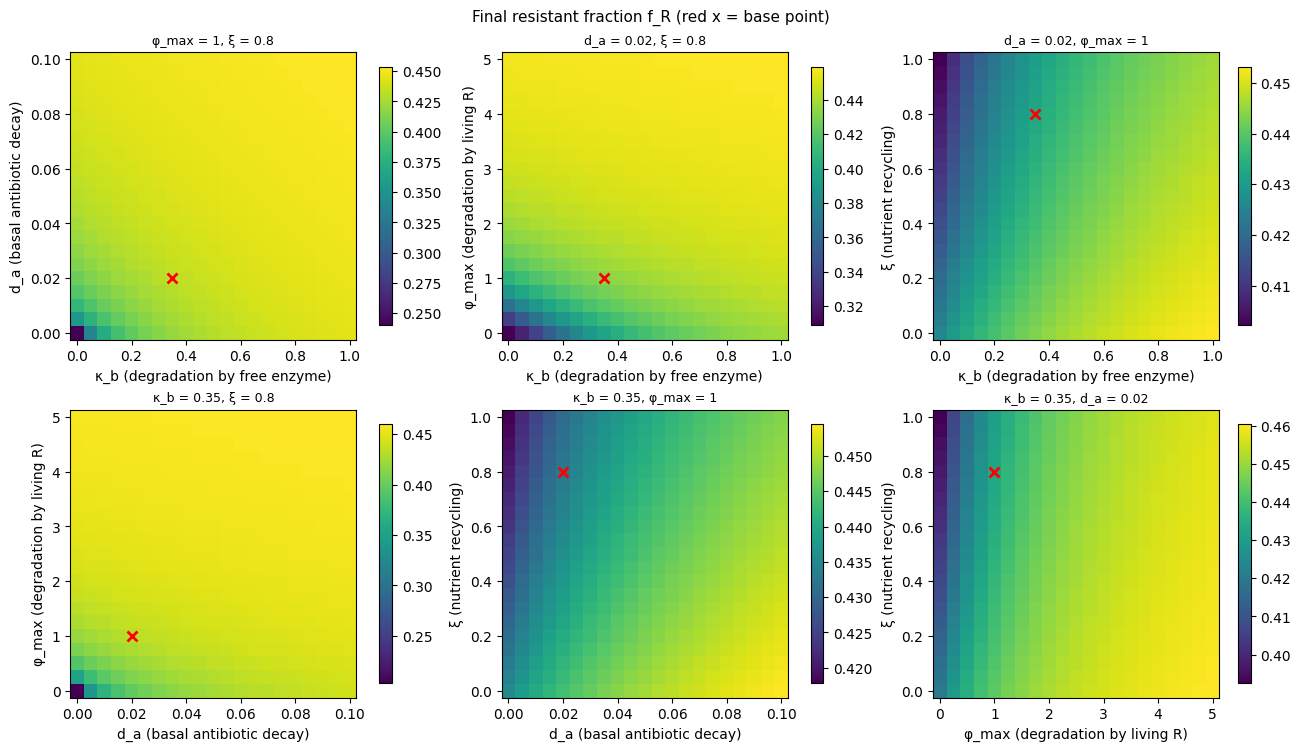

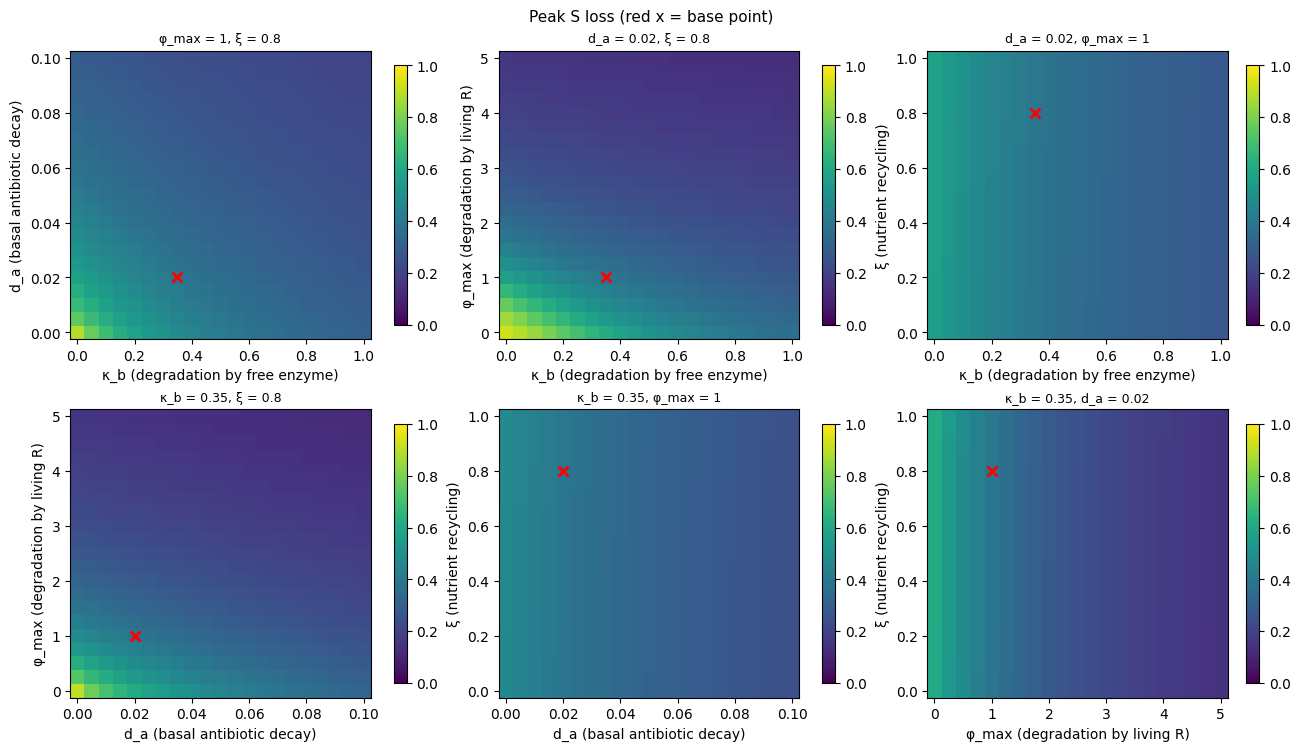

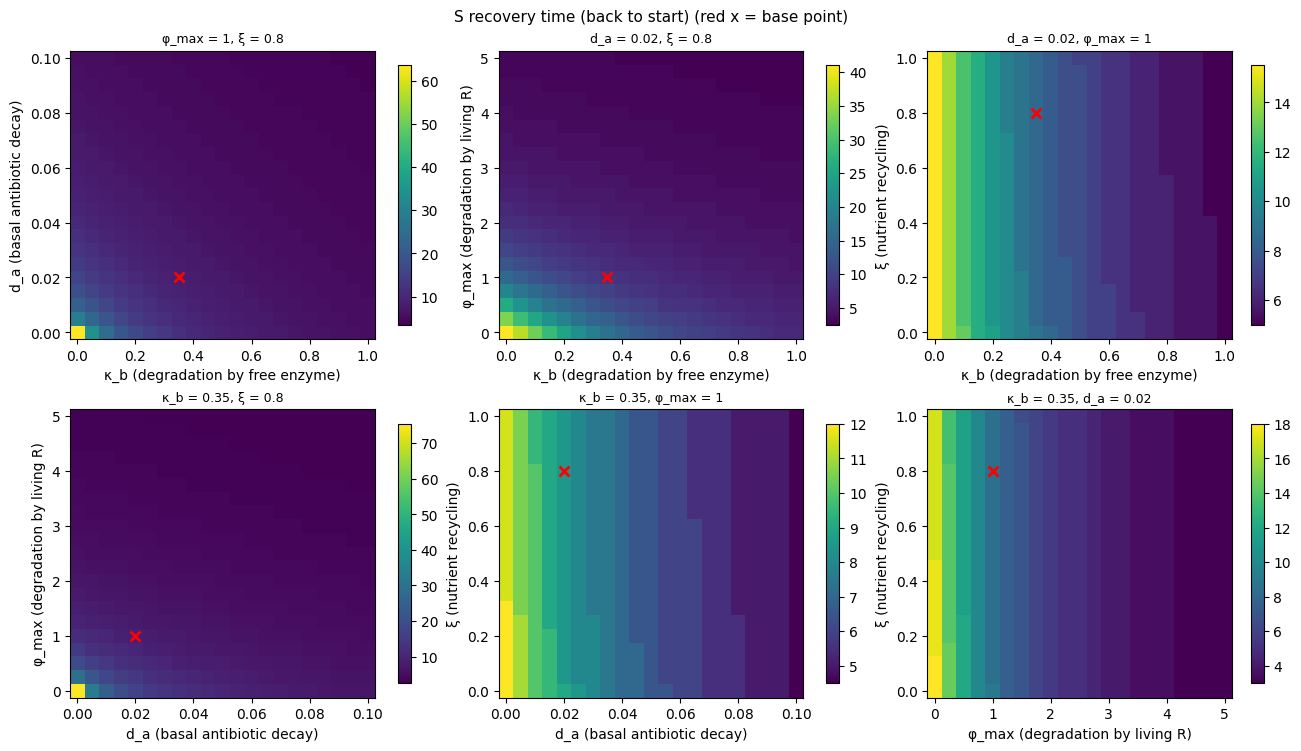

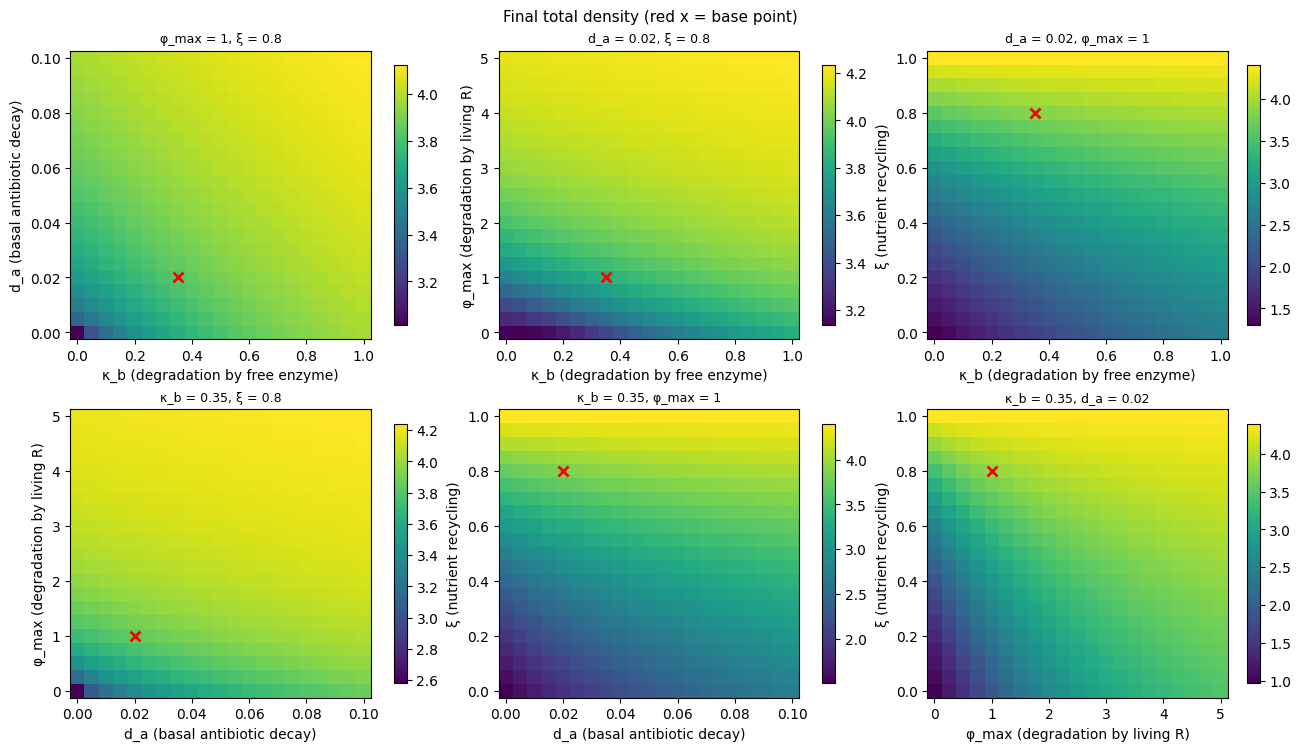

In [5]:
for col, kw in [("f_R_final", {}), ("peak_loss_S", {"vmin": 0, "vmax": 1}), ("t_regain_S", {}), ("total_final", {})]:
    pair_heatmaps(df, PARAMS, col, **kw); plt.show()

## Degradation by free enzyme (κ_b) vs. by living R (φ_max), for three values of basal decay d_a

Blank cells in the d_a = 0 panels are collapsed runs (no defined composition or recovery time). The red cross is shown in the base panel (d_a = 0.02).

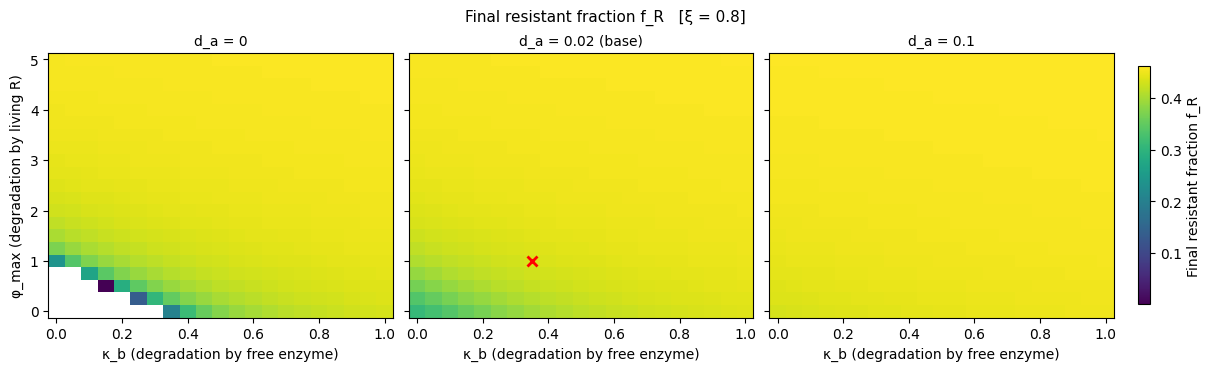

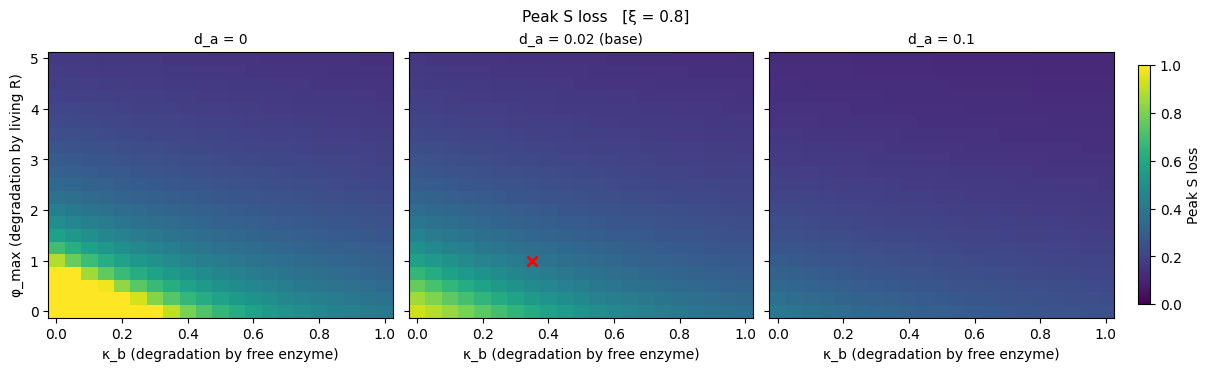

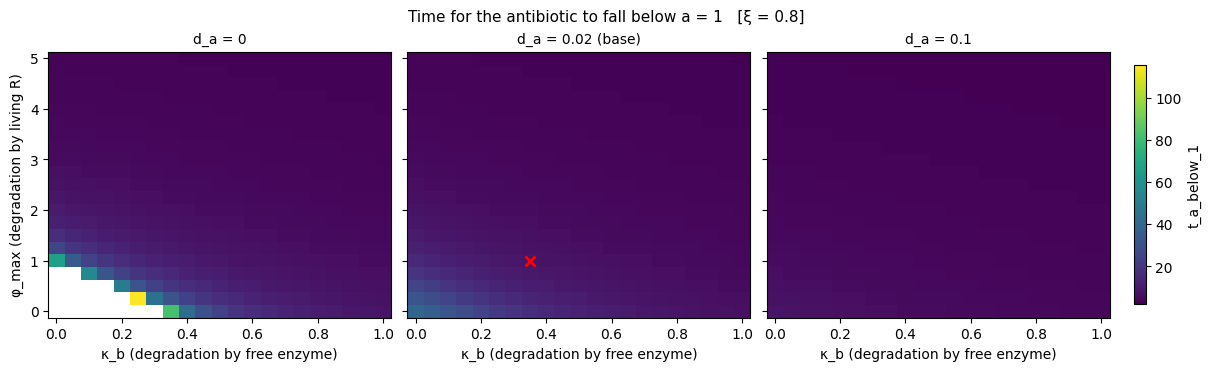

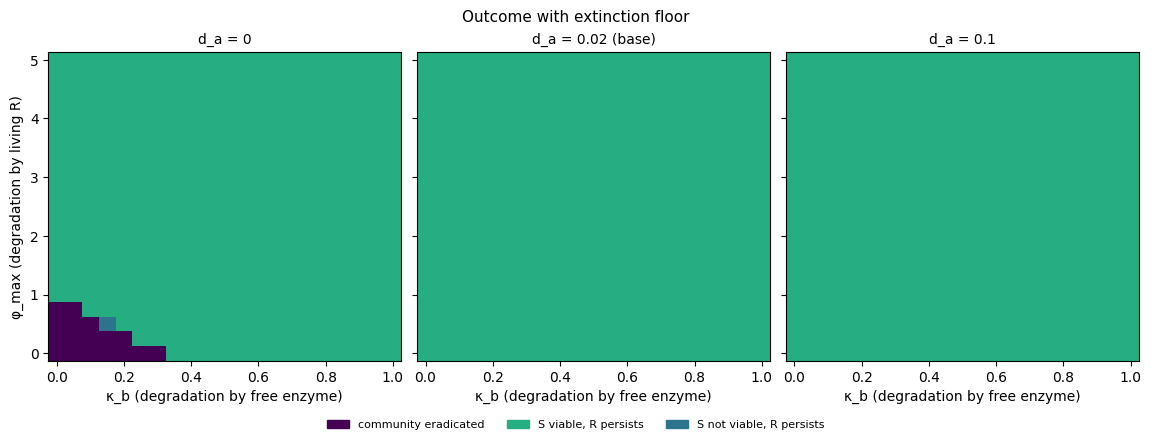

In [6]:
SL = [0.0, 0.02, 0.1]
heatmap_slices(df, "kappa_b", "phi_max", "f_R_final", "d_a", SL, fixed={"xi": 0.8}); plt.show()
heatmap_slices(df, "kappa_b", "phi_max", "peak_loss_S", "d_a", SL, fixed={"xi": 0.8}, vmin=0, vmax=1); plt.show()
heatmap_slices(df, "kappa_b", "phi_max", "t_a_below_1", "d_a", SL, fixed={"xi": 0.8},
               title="Time for the antibiotic to fall below a = 1"); plt.show()
outcome_map(df, "kappa_b", "phi_max", "d_a", SL, fixed={"xi": 0.8}); plt.show()

## Effect of each parameter

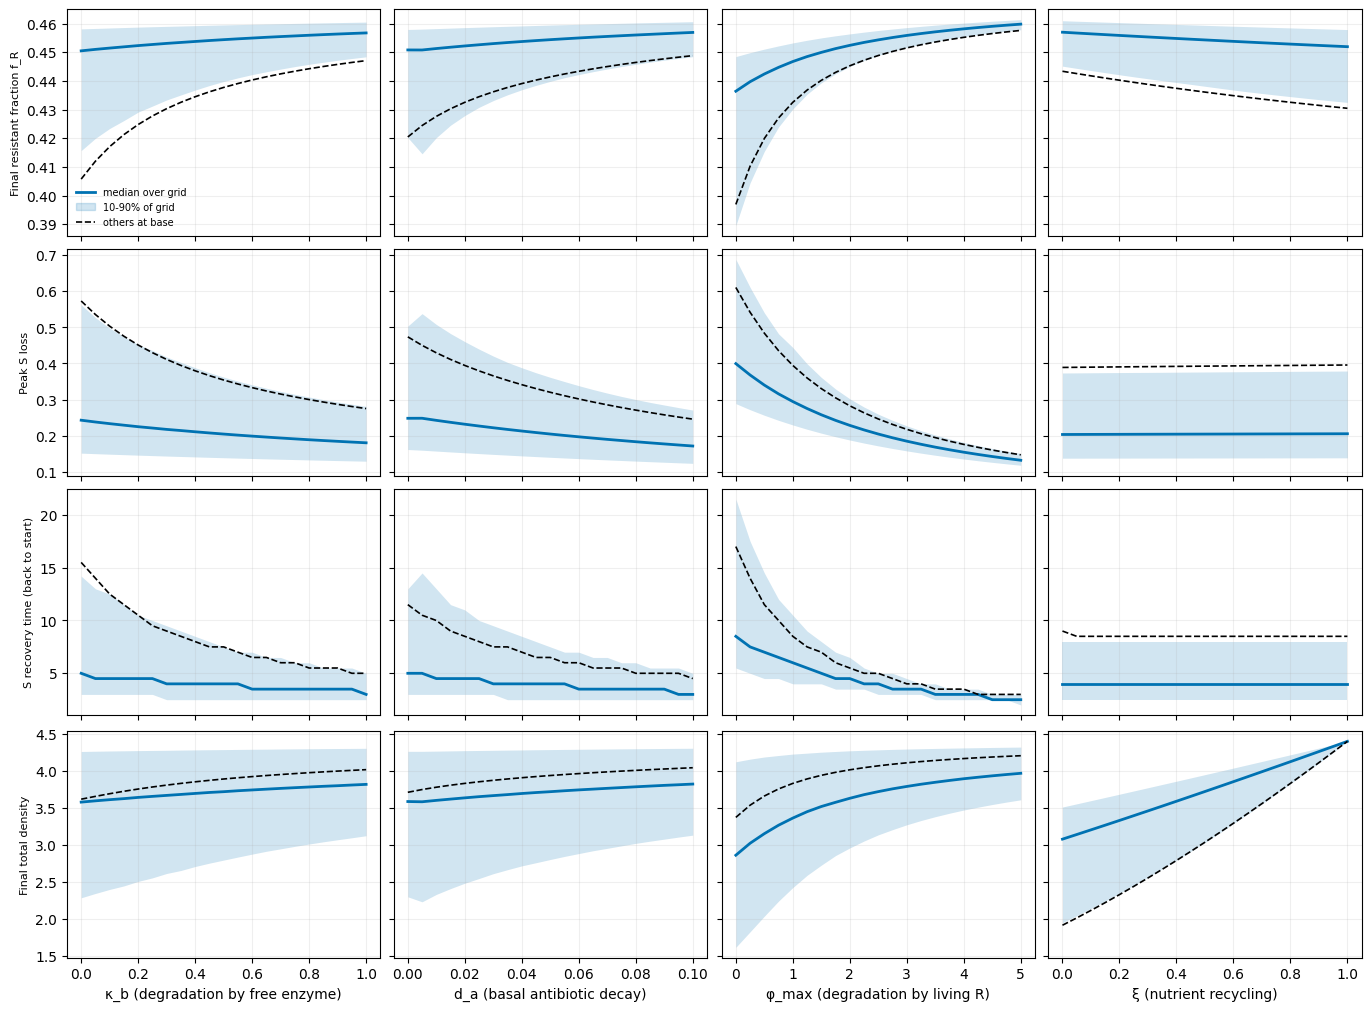

In [7]:
marginal_effects(settled, PARAMS, ["f_R_final", "peak_loss_S", "t_regain_S", "total_final"]); plt.show()

## Example time courses

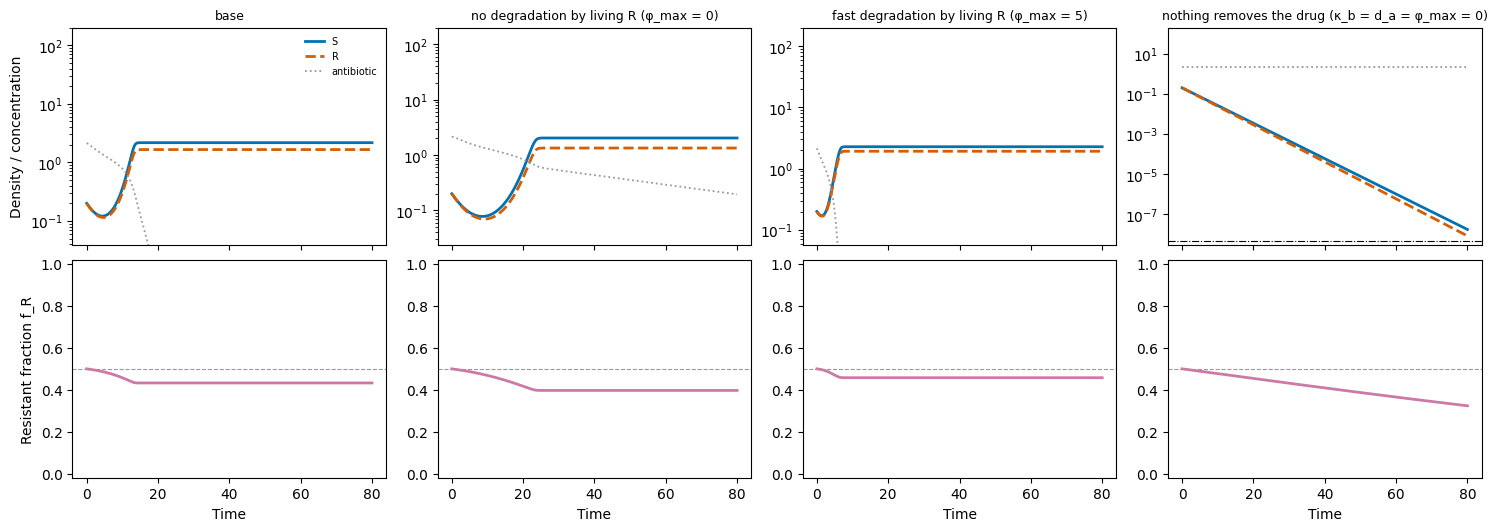

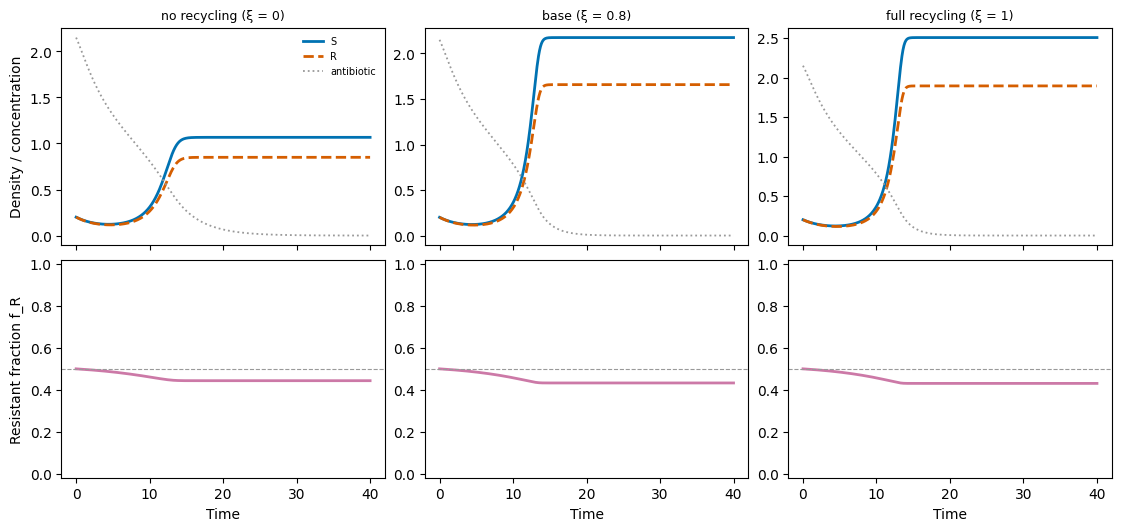

In [8]:
timecourses([("base", {}), ("no degradation by living R (φ_max = 0)", {"phi_max": 0.0}),
             ("fast degradation by living R (φ_max = 5)", {"phi_max": 5.0}),
             ("nothing removes the drug (κ_b = d_a = φ_max = 0)", {"kappa_b": 0.0, "d_a": 0.0, "phi_max": 0.0})],
            t_end=80); plt.show()
timecourses([("no recycling (ξ = 0)", {"xi": 0.0}), ("base (ξ = 0.8)", {}), ("full recycling (ξ = 1)", {"xi": 1.0})],
            t_end=40, log_y=False); plt.show()

## Rank sensitivity over the whole grid

In [9]:
ends = ["f_R_final", "diversity_final", "total_final", "peak_loss_S", "t_regain_S", "t_steady_state"]
rho = pd.DataFrame({label(e): [settled[[p, e]].corr(method="spearman").iloc[0, 1] for p in PARAMS] for e in ends},
                   index=[SHORT[p] for p in PARAMS])
print("Spearman rank correlation between each parameter and each endpoint, over the whole grid:")
rho.round(2)

Spearman rank correlation between each parameter and each endpoint, over the whole grid:


,Final resistant fraction f_R,Final Shannon diversity H,Final total density,Peak S loss,S recovery time (back to start),Time to steady state
κ_b,0.28,0.28,0.13,-0.24,-0.29,-0.28
d_a,0.30,0.30,0.14,-0.31,-0.31,-0.30
φ_max,0.86,0.86,0.43,-0.91,-0.88,-0.90
ξ,-0.24,-0.24,0.84,0.01,-0.01,-0.07


## Takeaways

- **These parameters change the crash and the recovery, not who wins.** S gains in every run (R never
  gains), and 91.5% of settled runs end with f_R between 0.38 and 0.46 (99% between 0.38 and 0.47).
- **Degradation by living resistant cells (φ_max) dominates** (rank correlations: −0.91 with peak S
  loss, −0.88 with recovery time, +0.86 with f_R). At base values of the others, going from φ_max = 0
  to 5 cuts peak S loss from 61% to 15% and recovery time from 17 to 3, and raises f_R from 0.40 to
  0.46. At the base traits R loses share whenever cells grow, with or without drug (its growth cost
  1 − α exceeds what its protection saves); a shorter exposure means a shallower crash and less
  regrowth, so R loses less.
- **κ_b and d_a act the same way but more weakly** (median peak S loss 24% → 18% and 25% → 17% over
  their ranges).
- **ξ mainly sets how much biomass comes back.** At base, the final total rises from 1.92
  (ξ = 0) to 4.40 (ξ = 1) with almost no change in crash depth. Its effect on composition is as small
  as that of κ_b and d_a (rank correlation with f_R −0.24).
- **"S not viable" here means low biomass, not R taking over.** 2.9% of runs end with S below the
  viability line; they sit at low ξ (median 0.10) with f_R still about 0.43. S is below the line
  because the whole community regrows to a small size.
- **The community collapses only when the antibiotic is removed too slowly.** 350 runs (0.18%) collapse, all
  with d_a = 0, κ_b ≤ 0.3 and φ_max ≤ 0.75 (3.8% of the d_a = 0 slice). No run with d_a > 0
  collapses on this grid (smallest non-zero d_a: 0.005). Three more d_a = 0 runs had not settled by
  t = 2400 (S still declining in two, slowly regrowing in one) and are marked not converged.
- **Slow cases exist:** 109 settled runs needed a horizon beyond t = 150 (longest time to steady state:
  1,138). A fixed horizon of 150 would have mis-reported them.
- **Caveat.** The d_a range (0-0.1) is the group's choice; the paper does not randomize d_a.